# 01 · Dataset overview

Patient-level description of the datasets, from the training manifests (`dataset_manifest.csv`), the frames on disk
and, when present, `data/video_data.csv` (pseudonymised patients, demographics). A missing manifest is skipped.

| Key | Dataset | Task | Grades |
|---|---|---|---|
| `mes` | internal, UC | Mayo endoscopic subscore | 0–3 |
| `ulcer` | internal, CD | Ulcer vs normal mucosa | 0–1 |
| `limuc` | LIMUC (public) | Mayo endoscopic subscore | 0–3 (one image per clip) |

Outputs are aggregate counts only: no study or patient ID, path or frame.

In [12]:
%matplotlib inline
import contextlib
import io
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from IPython.display import display
from PIL import Image

ROOT = Path("..")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.tools.cohort_inventory import TASKS, checks, demographics, split_table  # noqa: E402
from src.data.dataloader import _sampling_train, describe_subset  # noqa: E402
from src.data.manifest_utils import (  # noqa: E402
    SPLITS,
    find_duplicate_frames,
    load_manifest,
    load_video_data,
    report_duplicate_frames,
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
SPLITS = list(SPLITS)

MES_GRADES = {0: "Mayo 0", 1: "Mayo 1", 2: "Mayo 2", 3: "Mayo 3"}
PLAN = ROOT / "configs/experiments/data_efficiency.yaml"
DATASETS = {  # linkage: `dataset` value in video_data.csv (None: no procedure-level data)
    "mes":   {"title": TASKS["mes"], "dir": ROOT / "data/mes", "grades": MES_GRADES, "plan": PLAN,
              "linkage": "mes"},
    "ulcer": {"title": TASKS["ulcer"], "dir": ROOT / "data/ulcer", "grades": {0: "Normal", 1: "Ulcer"},
              "plan": PLAN, "linkage": "ulcer"},
    "limuc": {"title": "UC (MES), LIMUC", "dir": ROOT / "data_LIMUC/mes", "grades": MES_GRADES,
              "plan": ROOT / "configs/experiments/data_efficiency_limuc.yaml", "linkage": None},
}
VIDEO_DATA = ROOT / "data/video_data.csv"

CHECK_FILES = True       # open every frame header (missing files, image size)
CHECK_DUPLICATES = True  # md5 of every frame (reads all images, about a minute)
MIN_CELL = 5             # per-split demographics hidden below this many patients

## 1. Manifests and patient linkage

Manifests with a `procedure_id` column are patient-level; older ones (one procedure per `patient_id`) are linked to
patients through `video_data.csv`, else a procedure counts as a patient.

In [13]:
video_data = load_video_data(VIDEO_DATA)  # None when absent


def to_patient_level(df: pd.DataFrame, linkage: str | None) -> tuple[pd.DataFrame, str]:
    # Returns the manifest with patient_id = patient (procedure_id = procedure when known) and the linkage source.
    if "procedure_id" in df.columns:
        return df, "manifest"
    if linkage is None:
        return df, "dataset (no procedures)"
    if video_data is None:
        return df.assign(procedure_id=df["patient_id"]), "none (procedure = patient)"
    patient = df["patient_id"].map(video_data.loc[video_data["dataset"] == linkage, "patient_id"])
    n_unmatched = df.loc[patient.isna(), "patient_id"].nunique()
    df = df.assign(procedure_id=df["patient_id"], patient_id=patient.fillna(df["patient_id"]))
    return df, "video_data.csv" + (f" ({n_unmatched} procedures unmatched)" if n_unmatched else "")


manifests, written_units, rows = {}, {}, []
for key, ds in DATASETS.items():
    path = ds["dir"] / "splits/dataset_manifest.csv"
    if not path.is_file():
        print(f"[{key}] no manifest, skipped")
        continue
    raw = load_manifest(path)
    written_units[key] = raw.groupby("split")["patient_id"].nunique()  # unit counted in split_info.json
    df, source = to_patient_level(raw, ds["linkage"])
    df["grade"] = df["label"].map(ds["grades"])
    manifests[key] = df
    rows.append({"dataset": key, "task": ds["title"], "patients": df["patient_id"].nunique(),
                 "procedures": df["procedure_id"].nunique() if "procedure_id" in df else "-",
                 "clips": df["clip_key"].nunique(), "frames": len(df), "linkage": source})
display(pd.DataFrame(rows).set_index("dataset"))

  [video_data] dropped 4 exact duplicate row(s)


,task,patients,procedures,clips,frames,linkage
dataset,,,,,,
mes,UC (MES),83,85,200,11683,manifest
ulcer,CD (ulcer),46,47,206,6238,manifest
limuc,"UC (MES), LIMUC",565,-,11267,11277,dataset (no procedures)


## 2. Counts per split and grade

`cohort_inventory.split_table`; grade `all` = any grade, split `total` = all splits.

In [14]:
for key, df in manifests.items():
    table = pd.concat([split_table(df), split_table(df.assign(split="total"))], ignore_index=True)
    table["grade"] = table.pop("label").map(lambda v: DATASETS[key]["grades"].get(v, v))
    if "procedure_id" not in df.columns:
        table = table.drop(columns="procedures")
    print(DATASETS[key]["title"])
    display(table.set_index(["split", "grade"]))

UC (MES)


patients  procedures  clips  frames
split grade                                      
train Mayo 0        30          30     36    1058
      Mayo 1        10          10     10     919
      Mayo 2        12          13     20    2554
      Mayo 3         3           3      3     390
      all           33          34     69    4921
val   Mayo 0        15          15     21     553
      Mayo 1         3           3      3     191
      Mayo 2         6           6     11     467
      Mayo 3         2           2      5     231
      all           16          16     40    1442
test  Mayo 0        31          31     42    1311
      Mayo 1        10          10     14    1522
      Mayo 2        15          16     25    1864
      Mayo 3         6           6     10     623
      all           34          35     91    5320
total Mayo 0        76          76     99    2922
      Mayo 1        23          23     27    2632
      Mayo 2        33          35     56    4885
      Mayo 3        11          11     18    1244
      all           83          85    200   11683

CD (ulcer)


patients  procedures  clips  frames
split grade                                      
train Normal        15          15     45    1596
      Ulcer         17          17     42    1140
      all           18          18     87    2736
val   Normal         7           7     16     599
      Ulcer          8           8     16     377
      all            9           9     32     976
test  Normal        17          18     46    1592
      Ulcer         17          17     41     934
      all           19          20     87    2526
total Normal        39          40    107    3787
      Ulcer         42          42     99    2451
      all           46          47    206    6238

UC (MES), LIMUC


patients  clips  frames
split grade                          
train Mayo 0       361   4498    4498
      Mayo 1       307   2202    2202
      Mayo 2       198    867     867
      Mayo 3       125    632     632
      all          395   8189    8199
val   Mayo 0        76    753     753
      Mayo 1        62    444     444
      Mayo 2        42    225     225
      Mayo 3        25    134     134
      all           85   1556    1556
test  Mayo 0        73    854     854
      Mayo 1        58    406     406
      Mayo 2        39    163     163
      Mayo 3        26     99      99
      all           85   1522    1522
total Mayo 0       510   6105    6105
      Mayo 1       427   3052    3052
      Mayo 2       279   1255    1255
      Mayo 3       176    865     865
      all          565  11267   11277

## 3. Class balance

Share of each grade in a split's frames, and patients by their highest grade (the val stratum of the temporal split).

UC (MES)


% of frames                   patients by highest grade               
split        train   val  test total                     train val test total
Mayo 0        21.5  38.3  24.6  25.0                        14   7   12    33
Mayo 1        18.7  13.2  28.6  22.5                         5   2    4    11
Mayo 2        51.9  32.4  35.0  41.8                        11   5   12    28
Mayo 3         7.9  16.0  11.7  10.6                         3   2    6    11

CD (ulcer)


% of frames                   patients by highest grade               
split        train   val  test total                     train val test total
Normal        58.3  61.4  63.0  60.7                         1   1    2     4
Ulcer         41.7  38.6  37.0  39.3                        17   8   17    42

UC (MES), LIMUC


% of frames                   patients by highest grade               
split        train   val  test total                     train val test total
Mayo 0        54.9  48.4  56.1  54.1                        50  12   14    76
Mayo 1        26.9  28.5  26.7  27.1                       123  25   27   175
Mayo 2        10.6  14.5  10.7  11.1                        97  23   18   138
Mayo 3         7.7   8.6   6.5   7.7                       125  25   26   176

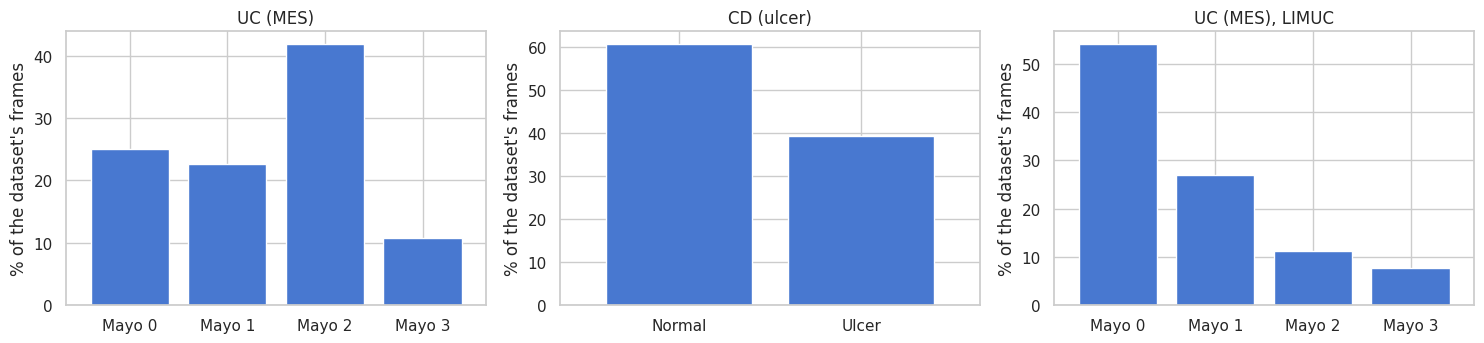

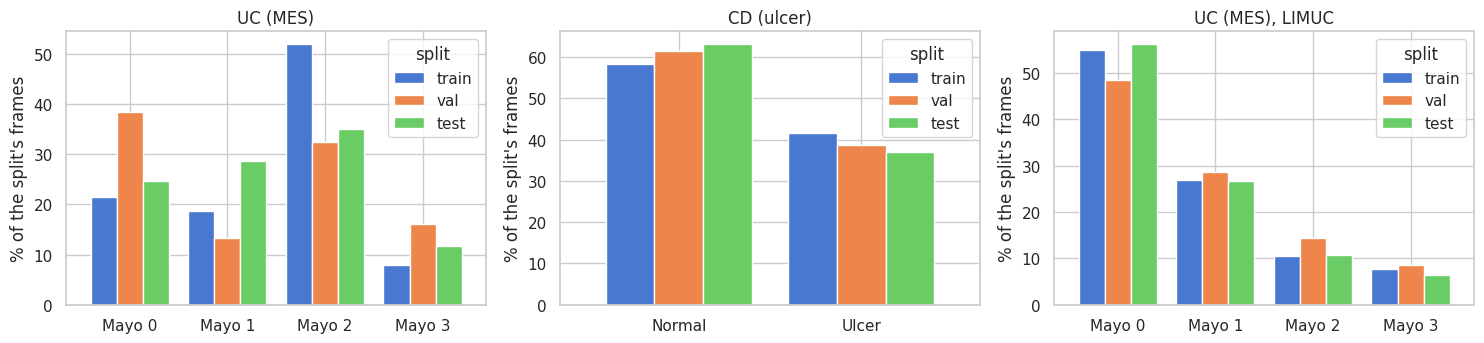

In [15]:
balance = {}
for key, df in manifests.items():
    grades = list(DATASETS[key]["grades"].values())
    frames = pd.crosstab(df["grade"], df["split"], normalize="columns").mul(100)
    frames = frames.reindex(index=grades, columns=SPLITS).fillna(0)
    frames["total"] = df["grade"].value_counts(normalize=True).mul(100).reindex(grades).fillna(0)
    top = df.groupby(["split", "patient_id"])["label"].max().map(DATASETS[key]["grades"]).reset_index()
    patients = pd.crosstab(top["label"], top["split"]).reindex(index=grades, columns=SPLITS, fill_value=0)
    patients["total"] = patients.sum(axis=1)
    balance[key] = frames
    print(DATASETS[key]["title"])
    display(pd.concat({"% of frames": frames.round(1), "patients by highest grade": patients}, axis=1))

fig, axes = plt.subplots(1, len(balance), figsize=(5 * len(balance), 3.6), squeeze=False)
for ax, (key, frames) in zip(axes[0], balance.items()):
    frames["total"].plot.bar(ax=ax, rot=0, width=0.8)
    ax.set(title=DATASETS[key]["title"], xlabel="", ylabel="% of the dataset's frames")
fig.tight_layout()

fig2, axes2 = plt.subplots(1, len(balance), figsize=(5 * len(balance), 3.6), squeeze=False)
for ax, (key, frames) in zip(axes2[0], balance.items()):
    frames[SPLITS].plot.bar(ax=ax, rot=0, width=0.8)
    ax.set(title=DATASETS[key]["title"], xlabel="", ylabel="% of the split's frames")
fig2.tight_layout()
plt.show()

## 4. Clip length

Median [IQR] (min–max). Span: clip length in source-video frames, from the `__f_<index>` frame names (MES only).

In [16]:
def iqr(values: pd.Series) -> str:
    if values.empty:
        return "-"
    q1, med, q3 = values.quantile([0.25, 0.5, 0.75])
    return f"{med:g} [{q1:g}–{q3:g}] ({values.min():g}–{values.max():g})"


for key, df in manifests.items():
    grades = list(DATASETS[key]["grades"].values())
    clips = df.groupby("clip_key").agg(split=("split", "first"), patient=("patient_id", "first"),
                                       label=("label", lambda s: int(s.mode().iloc[0])), frames=("label", "size"))
    clips["grade"] = clips["label"].map(DATASETS[key]["grades"])
    print(DATASETS[key]["title"])

    single_image = clips["frames"].median() == 1
    if single_image:
        print(f"one image per clip ({int((clips['frames'] > 1).sum())} clips of 2+ images)")
    else:
        source = df["relative_path"].str.extract(r"__f_(\d+)\.\w+$")[0].astype(float)
        aggs = {"clips": ("frames", "size"), "frames / clip": ("frames", iqr)}
        if source.notna().all():
            ordered = df.assign(source=source).sort_values(["clip_key", "source"])
            steps = ordered.groupby("clip_key")["source"].diff().dropna()
            step = steps.mode().iloc[0]
            clips["span"] = ordered.groupby("clip_key")["source"].agg(lambda s: s.max() - s.min()) + step
            aggs["span (source frames)"] = ("span", iqr)
            print(f"one frame every {step:g} source frames ({(steps == step).mean():.0%} of consecutive pairs)")
        by_grade = pd.concat([clips, clips.assign(split="total")]).groupby(["split", "grade"]).agg(**aggs)
        order = [(s, g) for s in SPLITS + ["total"] for g in grades if (s, g) in by_grade.index]
        display(by_grade.reindex(order))

    per_patient = clips.groupby(["split", "patient"]).agg(clips=("frames", "size"), frames=("frames", "sum"),
                                                         grades=("label", "nunique"))
    if single_image:
        per_patient = per_patient.drop(columns="clips")
    per_patient = pd.concat([per_patient, per_patient.rename(index=lambda s: "total", level="split")])
    display(per_patient.groupby(level="split").agg(iqr).reindex(SPLITS + ["total"])
            .add_suffix(" / patient"))

UC (MES)
one frame every 60 source frames (62% of consecutive pairs)


clips              frames / clip              span (source frames)
split grade                                                                     
train Mayo 0     36        41 [13.5–43] (2–44)    10890 [3165–35643] (180–91980)
      Mayo 1     10   44 [30.25–58.25] (7–419)    3180 [2490–14460] (1800–70669)
      Mayo 2     20     47 [16.75–150] (8–701)  5127.5 [3090–14640] (1080–69051)
      Mayo 3      3     69 [58.5–171] (48–273)    9720 [6300–16500] (2880–23280)
val   Mayo 0     21          29 [10–43] (2–44)    11400 [2340–24300] (360–79380)
      Mayo 1      3         55 [29–94] (3–133)      3780 [2010–9150] (240–14520)
      Mayo 2     11     48 [11.5–70.5] (2–100)       3120 [870–5520] (120–10200)
      Mayo 3      5          32 [7–35] (4–153)      3300 [3060–3420] (240–15120)
test  Mayo 0     42     41.5 [20.25–43] (2–44)   12990 [4335–33450] (240–113040)
      Mayo 1     14  60.5 [29.5–143.5] (4–474)   6536.5 [2295–19155] (240–79680)
      Mayo 2     25         39 [13–89] (5–469)     5760 [1080–10080] (300–42360)
      Mayo 3     10  32 [14.75–90.75] (12–173)    7050 [2850–14985] (1920–40380)
total Mayo 0     99        38 [12.5–43] (2–44)   11400 [4020–33930] (180–113040)
      Mayo 1     27      52 [27–122.5] (3–474)     3840 [2220–17880] (240–79680)
      Mayo 2     56       43.5 [13–90] (2–701)      4770 [1335–9810] (120–69051)
      Mayo 3     18   38 [14.75–90.75] (4–273)     5010 [2895–14940] (240–40380)

,clips / patient,frames / patient,grades / patient
split,,,
train,2 [1–3] (1–5),51 [43–130] (37–950),2 [1–2] (1–3)
val,2 [1–2.25] (1–12),48.5 [43–109.5] (23–303),1.5 [1–2] (1–3)
test,2 [2–3] (1–8),81.5 [43–192.25] (31–903),2 [1–2] (1–3)
total,2 [1–3] (1–12),68 [43–147] (23–950),2 [1–2] (1–3)


CD (ulcer)
one frame every 6 source frames (96% of consecutive pairs)


clips          frames / clip     span (source frames)
split grade                                                        
train Normal     45      33 [26–49] (9–50)  228 [168–300] (120–300)
      Ulcer      42   23.5 [20–30] (10–50)   144 [120–180] (60–300)
val   Normal     16  42 [20–49.25] (18–50)  255 [120–300] (108–300)
      Ulcer      16    20 [17.5–30] (8–50)    120 [95–180] (33–300)
test  Normal     46   30 [26.25–46] (7–50)   180 [180–300] (42–300)
      Ulcer      41      20 [17–30] (6–50)    120 [63–180] (33–300)
total Normal    107      36 [26–48] (7–50)   240 [171–300] (42–300)
      Ulcer      99    20 [18.5–30] (6–50)    120 [94–180] (33–300)

,clips / patient,frames / patient,grades / patient
split,,,
train,4.5 [2–7] (2–11),144 [58.5–243.75] (29–353),2 [2–2] (1–2)
val,2 [2–4] (1–10),80 [44–98] (20–335),2 [1–2] (1–2)
test,4 [2.5–5.5] (2–13),97 [65–174.5] (46–470),2 [2–2] (1–2)
total,4 [2–6] (1–13),95.5 [58.5–184.25] (20–470),2 [2–2] (1–2)


UC (MES), LIMUC
one image per clip (10 clips of 2+ images)


,frames / patient,grades / patient
split,,
train,16 [9–28] (1–105),2 [2–3] (1–4)
val,15 [7–25] (1–73),2 [2–3] (1–4)
test,13 [7–24] (1–91),2 [2–3] (1–4)
total,15 [8–27] (1–105),2 [2–3] (1–4)


## 5. Frames on disk and duplicates

Every manifest frame must be readable; sizes are as stored (the loaders resize and apply CLAHE). Duplicates: groups of
byte-identical frames (`find_duplicate_frames`); groups across patients or splits would leak.

In [17]:
disk = {}
for key, df in manifests.items():
    root = DATASETS[key]["dir"] / "processed"
    if not (CHECK_FILES and root.is_dir()):
        continue
    sizes = []
    for rel in df["relative_path"]:
        try:
            with Image.open(root / rel) as im:
                sizes.append((f"{im.width}×{im.height}", im.mode))
        except OSError:
            sizes.append(("unreadable", "unreadable"))
    disk[key] = pd.DataFrame(sizes, columns=["size", "mode"])

def top_values(values: pd.Series, n: int = 3) -> str:
    counts = values.value_counts()
    text = ", ".join(f"{v} ({c})" for v, c in counts.head(n).items())
    return text + (f", +{len(counts) - n} more" if len(counts) > n else "")


if disk:
    display(pd.DataFrame({key: {
        "frames": len(s),
        "missing / unreadable": int((s["mode"] == "unreadable").sum()),
        "sizes (frames)": top_values(s.loc[s["mode"] != "unreadable", "size"]),
        "modes (frames)": top_values(s.loc[s["mode"] != "unreadable", "mode"]),
    } for key, s in disk.items()}))
else:
    print("frames not checked")

,mes,ulcer,limuc
frames,11683,6238,11277
missing / unreadable,0,0,0
sizes (frames),1350×1080 (11683),1350×1080 (6238),"352×288 (11276), 1350×1080 (1)"
modes (frames),RGB (11683),RGB (6238),RGB (11277)


In [18]:
DUPLICATE_STATS = {
    "n_duplicate_rows": "frames in duplicate groups",
    "n_distinct_images": "duplicate groups",
    "n_excess_rows": "excess copies",
    "n_cross_clip_copies": "copies in another clip",
    "n_groups_cross_clip": "groups across clips",
    "n_groups_cross_patient": "groups across patients",
    "n_groups_cross_label": "groups across grades",
    "n_groups_cross_split": "groups across splits",
}
duplicates = {}
for key, df in manifests.items():
    root = DATASETS[key]["dir"] / "processed"
    if not (CHECK_DUPLICATES and root.is_dir()):
        continue
    with contextlib.redirect_stdout(io.StringIO()):  # its printed report names clips
        duplicates[key] = report_duplicate_frames(find_duplicate_frames(df, root), max_pairs=0)

if duplicates:
    display(pd.DataFrame(duplicates).reindex(list(DUPLICATE_STATS)).fillna(0).astype(int)
            .rename(index=DUPLICATE_STATS))
else:
    print("duplicates not checked")

,mes,ulcer,limuc
frames in duplicate groups,20,231,20
duplicate groups,9,40,10
excess copies,11,191,10
copies in another clip,0,0,0
groups across clips,0,0,0
groups across patients,0,0,0
groups across grades,0,0,10
groups across splits,0,0,0


## 6. Demographics

Age and sex over patients at their first procedure (`cohort_inventory.demographics`; gender 1 = female). Splits with
fewer than `MIN_CELL` patients are not shown; the range is given for the whole cohort only.

In [19]:
def demographics_table(df: pd.DataFrame, dataset: str) -> pd.DataFrame:
    rows = {}
    for split in SPLITS + ["total"]:
        d = demographics(df if split == "total" else df[df["split"] == split], video_data, dataset)
        n, age, female = d.get("patients", 0), d.get("age"), d.get("female")
        shown = n >= MIN_CELL or split == "total"
        rows[split] = {
            "patients": n,
            "age, mean (SD)": (f"{age['mean']} ({age['sd']})" if age else "-") if shown else f"n < {MIN_CELL}",
            "female, n (%)": (f"{female['n']} ({female['pct']})" if female else "-") if shown else f"n < {MIN_CELL}",
            "age, median (range)": (f"{age['median']:g} ({age['min']:g}–{age['max']:g})"
                                    if split == "total" and age else ""),
        }
    print(f"procedures: {d['procedures_matched']} matched, {d['procedures_only_in_manifest']} only in the "
          f"manifest, {d['procedures_only_in_video_data']} only in video_data.csv")
    return pd.DataFrame(rows).T


if video_data is None:
    print("video_data.csv not found: no demographics")
for key, df in manifests.items():
    if video_data is not None and DATASETS[key]["linkage"]:
        print(DATASETS[key]["title"])
        display(demographics_table(df, DATASETS[key]["linkage"]))

UC (MES)
procedures: 85 matched, 0 only in the manifest, 14 only in video_data.csv


,patients,"age, mean (SD)","female, n (%)","age, median (range)"
train,33,50.8 (16.7),17 (51.5),
val,16,44.1 (17.3),11 (68.8),
test,34,50.0 (17.6),18 (52.9),
total,83,49.2 (17.2),46 (55.4),50 (19–79)


CD (ulcer)
procedures: 47 matched, 0 only in the manifest, 4 only in video_data.csv


,patients,"age, mean (SD)","female, n (%)","age, median (range)"
train,18,38.7 (14.2),9 (50.0),
val,9,51.4 (15.8),5 (55.6),
test,19,42.4 (17.4),10 (52.6),
total,46,42.7 (16.2),24 (52.2),41 (19–82)


## 7. Integrity checks

Every count should be 0. `cohort_inventory.checks` adds patients shared by UC and CD and grades with fewer than 2
patients in a split.

In [20]:
def split_info_check(key: str, df: pd.DataFrame) -> tuple[str, str]:
    path = DATASETS[key]["dir"] / "splits/split_info.json"
    if not path.is_file():
        return "split_info.json not found", "-"
    info = json.loads(path.read_text(encoding="utf-8"))
    strategy = f"{info.get('split_strategy', info.get('strategy'))}, seed {info.get('random_seed')}"
    if info.get("test_cutoff"):
        strategy += f", test from {info['test_cutoff']}"
    diffs = []
    for split in SPLITS:
        s_info, sub = info.get("splits", {}).get(split, {}), df[df["split"] == split]
        counts = {str(k): int(v) for k, v in sub["label"].value_counts().items()}
        if s_info.get("n_frames", len(sub)) != len(sub):
            diffs.append(f"{split} frames")
        if s_info.get("n_patients", written_units[key].get(split, 0)) != written_units[key].get(split, 0):
            diffs.append(f"{split} units")
        if {str(k): int(v) for k, v in s_info.get("label_counts", counts).items()} != counts:
            diffs.append(f"{split} label counts")
    return strategy, ", ".join(diffs) or "identical"


def integrity(key: str, df: pd.DataFrame) -> dict:
    def n_multi(unit: str, attribute: str) -> int:
        return int((df.groupby(unit)[attribute].nunique() > 1).sum())

    grades = DATASETS[key]["grades"]
    present = set(zip(df["split"], df["label"]))
    strategy, agreement = split_info_check(key, df)
    return {
        "split strategy": strategy,
        "patients in more than one split": n_multi("patient_id", "split"),
        "procedures in more than one split": n_multi("procedure_id", "split") if "procedure_id" in df else "-",
        "clips in more than one split": n_multi("clip_key", "split"),
        "clips of several patients": n_multi("clip_key", "patient_id"),
        "clips with several grades": n_multi("clip_key", "label"),
        **{f"duplicate images across {unit}": (duplicates[key].get(f"n_groups_cross_{unit[:-1]}", 0)
                                               if key in duplicates else "not checked")
           for unit in ("patients", "splits")},
        "duplicated file paths": int(df["relative_path"].duplicated().sum()),
        "labels outside the grades": int((~df["label"].isin(grades)).sum()),
        "grades absent from a split": ", ".join(f"{name} ({s})" for s in SPLITS for lbl, name in grades.items()
                                                if (s, lbl) not in present) or 0,
        "frames missing on disk": (int((disk[key]["mode"] == "unreadable").sum()) if key in disk
                                   else "not checked"),
        "split_info.json agreement": agreement,
    }


display(pd.DataFrame({key: integrity(key, df) for key, df in manifests.items()}))

internal = {key: manifests[key] for key in ("mes", "ulcer") if key in manifests}
messages = checks(internal) + (checks({"limuc": manifests["limuc"]}) if "limuc" in manifests else [])
print("\n".join(messages) or "cohort_inventory.checks: no error or warning")

,mes,ulcer,limuc
split strategy,"stratified, seed 42","stratified, seed 42","stratified, seed 42"
patients in more than one split,0,0,0
procedures in more than one split,0,0,-
clips in more than one split,0,0,0
clips of several patients,0,0,0
clips with several grades,0,0,10
duplicate images across patients,0,0,0
duplicate images across splits,0,0,0
duplicated file paths,0,0,0
labels outside the grades,0,0,0


cohort_inventory.checks: no error or warning


## 8. Training subsets of the plan

The runners' sampler (`_sampling_train`) at every seed and fraction of the plan, described with `describe_subset`.
Each grade keeps the nominal fraction of its training frames: its clips in a random order per seed, the last one cut
to its first frames (`clips` counts the cut ones).
`% of grade`: of that grade's training frames; `% of subset`: grade mix (row 100 % = full train split).

UC (MES): 10 seeds, fractions 0.1, 0.25, 0.5, 0.75, 1; nested for every seed: True


% of grade (mean) % of grade (range)  % of subset (mean)  clips patients
fraction grade                                                                           
10       all                  10.0                 10               100.0   8–15     6–11
         Mayo 0               10.0                 10                21.5    3–9      3–8
         Mayo 1               10.0                 10                18.7    1–3      1–3
         Mayo 2               10.0                 10                51.8    1–6      1–5
         Mayo 3               10.0                 10                 7.9      1        1
25       all                  25.0                 25               100.0  17–26    13–18
         Mayo 0               25.0                 25                21.5   8–12     7–11
         Mayo 1               25.0                 25                18.7    1–7      1–7
         Mayo 2               25.0                 25                51.9   1–10      1–9
         Mayo 3               25.1               25.1                 8.0    1–2      1–2
50       all                  50.0                 50               100.0  27–42    22–27
         Mayo 0               50.0                 50                21.5  16–20    15–19
         Mayo 1               50.1               50.1                18.7    2–9      2–9
         Mayo 2               50.0                 50                51.9   5–14     5–10
         Mayo 3               50.0                 50                 7.9    1–3      1–3
75       all                  75.0                 75               100.0  46–58    28–32
         Mayo 0               75.0                 75                21.5  25–29    21–26
         Mayo 1               75.0                 75                18.7   4–10     4–10
         Mayo 2               75.0                 75                51.9   8–19     6–12
         Mayo 3               74.9               74.9                 7.9    2–3      2–3
100      all                 100.0                100               100.0     69       33
         Mayo 0              100.0                100                21.5     36       30
         Mayo 1              100.0                100                18.7     10       10
         Mayo 2              100.0                100                51.9     20       12
         Mayo 3              100.0                100                 7.9      3        3

CD (ulcer): 10 seeds, fractions 0.1, 0.25, 0.5, 0.75, 1; nested for every seed: True


% of grade (mean) % of grade (range)  % of subset (mean)  clips patients
fraction grade                                                                           
10       all                  10.0                 10               100.0   8–12     4–11
         Normal               10.0                 10                58.4    4–6      3–5
         Ulcer                10.0                 10                41.6    4–6      3–6
25       all                  25.0                 25               100.0  21–24    10–14
         Normal               25.0                 25                58.3  10–13      5–9
         Ulcer                25.0                 25                41.7   9–12     6–10
50       all                  50.0                 50               100.0  41–47    14–18
         Normal               50.0                 50                58.3  21–24     9–13
         Ulcer                50.0                 50                41.7  19–23     9–15
75       all                  75.0                 75               100.0  61–67    16–18
         Normal               75.0                 75                58.3  30–35    10–15
         Ulcer                75.0                 75                41.7  29–34    13–17
100      all                 100.0                100               100.0     87       18
         Normal              100.0                100                58.3     45       15
         Ulcer               100.0                100                41.7     42       17

UC (MES), LIMUC: 10 seeds, fractions 0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 1; nested for every seed: True


% of grade (mean) % of grade (range)  % of subset (mean)      clips patients
fraction grade                                                                               
1        all                   1.0                  1               100.0      81–82    66–76
         Mayo 0                1.0                  1                54.6      44–45    38–45
         Mayo 1                1.0                  1                27.1      22–23    17–23
         Mayo 2                1.0                  1                11.0          9      8–9
         Mayo 3                0.9                0.9                 7.3          6      5–6
5        all                   5.0                  5               100.0    408–410  206–225
         Mayo 0                5.0                  5                54.8    224–225  136–154
         Mayo 1                5.0                  5                26.9    110–111    77–85
         Mayo 2                5.0              5–5.1                10.5      43–44    35–39
         Mayo 3                5.1                5.1                 7.8         32    21–29
10       all                  10.0                 10               100.0    818–820  286–303
         Mayo 0               10.0                 10                54.8    448–450  193–224
         Mayo 1               10.0            10–10.1                26.9    220–222  128–137
         Mayo 2               10.0           9.9–10.1                10.6      86–88    61–68
         Mayo 3               10.0            10–10.1                 7.7      63–64    41–48
25       all                  25.0                 25               100.0  2044–2050  357–367
         Mayo 0               25.0            24.9–25                54.9  1122–1126  283–296
         Mayo 1               25.0            25–25.1                26.9    550–553  203–218
         Mayo 2               24.9            24.7–25                10.5    214–217  112–131
         Mayo 3               25.1            25–25.3                 7.7    158–160    71–81
50       all                  50.0                 50               100.0  4093–4098  383–390
         Mayo 0               50.0                 50                54.9  2248–2251  331–346
         Mayo 1               50.0            49.9–50                26.8  1098–1102  261–274
         Mayo 2               50.0          49.7–50.2                10.6    431–435  153–167
         Mayo 3               50.0          49.8–50.2                 7.7    315–317  100–110
75       all                  75.0                 75               100.0  6139–6145  390–394
         Mayo 0               75.0                 75                54.9  3372–3375  348–359
         Mayo 1               75.0          74.9–75.1                26.9  1649–1653  283–298
         Mayo 2               75.1            75–75.2                10.6    650–652  181–190
         Mayo 3               74.9            74.8–75                 7.7    473–474  111–121
100      all                 100.0                100               100.0       8189      395
         Mayo 0              100.0                100                54.9       4498      361
         Mayo 1              100.0                100                26.9       2202      307
         Mayo 2              100.0                100                10.6        867      198
         Mayo 3              100.0                100                 7.7        632      125

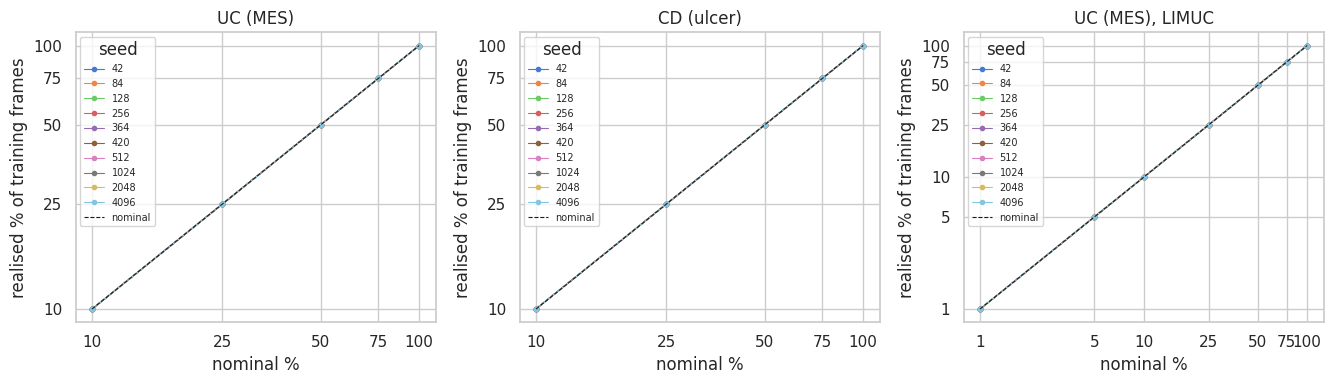

In [21]:
def read_plan(path: Path) -> tuple[list[float], list[int]]:
    plan = yaml.safe_load(Path(path).read_text(encoding="utf-8"))
    return sorted(float(r) for r in plan["subset_ratios"]), [int(s) for s in plan["seeds"]]


def value_range(values: pd.Series) -> str:
    return f"{values.min():g}" if values.min() == values.max() else f"{values.min():g}–{values.max():g}"


subsets = {}
for key, df in manifests.items():
    grades = DATASETS[key]["grades"]
    ratios, seeds = read_plan(DATASETS[key]["plan"])
    train = df[df["split"] == "train"]
    rows, nested = [], True
    for seed in seeds:
        previous = set()
        for ratio in ratios:
            sub = _sampling_train(train, ratio, "label", seed, verbose=False)
            info = describe_subset(sub, train)
            nested &= previous <= set(sub["relative_path"])
            previous = set(sub["relative_path"])
            rows.append({"seed": seed, "fraction": round(100 * ratio), "grade": "all",
                         "% of grade": 100 * info["realized_fraction"], "% of subset": 100.0,
                         "clips": info["n_clips"], "patients": info["n_patients"]})
            for lbl, name in grades.items():
                part = sub[sub["label"] == lbl]
                rows.append({"seed": seed, "fraction": round(100 * ratio), "grade": name,
                             "% of grade": 100 * info["class_realized_fraction"].get(str(lbl), np.nan),
                             "% of subset": 100 * info["class_frac"].get(str(lbl), np.nan),
                             "clips": part["clip_key"].nunique(), "patients": part["patient_id"].nunique()})
    sim = subsets[key] = pd.DataFrame(rows)
    summary = sim.groupby(["fraction", "grade"], sort=False).agg(**{
        "% of grade (mean)": ("% of grade", "mean"),
        "% of grade (range)": ("% of grade", lambda s: value_range(s.round(1))),
        "% of subset (mean)": ("% of subset", "mean"),
        "clips": ("clips", value_range),
        "patients": ("patients", value_range),
    })
    print(f"{DATASETS[key]['title']}: {len(seeds)} seeds, fractions {', '.join(f'{r:g}' for r in ratios)}; "
          f"nested for every seed: {nested}")
    display(summary.round(1))

fig, axes = plt.subplots(1, len(subsets), figsize=(4.5 * len(subsets), 4), squeeze=False)
for ax, (key, sim) in zip(axes[0], subsets.items()):
    overall = sim[sim["grade"] == "all"]
    for seed, grp in overall.groupby("seed"):
        ax.plot(grp["fraction"], grp["% of grade"], marker="o", markersize=3, linewidth=0.8, label=str(seed))
    ticks = sorted(overall["fraction"].unique())
    ax.plot([ticks[0], 100], [ticks[0], 100], "k--", linewidth=0.8, label="nominal")
    ax.set(xscale="log", yscale="log", title=DATASETS[key]["title"], xlabel="nominal %",
           ylabel="realised % of training frames")
    ax.set_xticks(ticks, [f"{t}" for t in ticks])
    ax.set_yticks(ticks, [f"{t}" for t in ticks])
    ax.minorticks_off()
    ax.legend(title="seed", fontsize=7)
fig.tight_layout()
plt.show()